<a href="https://colab.research.google.com/github/gayatri479/CSA4705-Deep-learning-B-SLOT/blob/main/CO3_Deep_Learning_Experiments_33_48.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 33. Compare SGD, RMSprop and Adam optimizers for defective product classification

SGD Test accuracy: 0.865 Test loss: 0.3379
RMSprop Test accuracy: 0.9375 Test loss: 0.1695
Adam Test accuracy: 0.93 Test loss: 0.1873


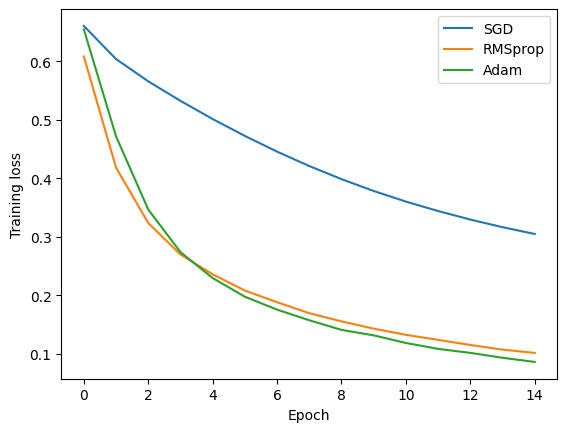

In [2]:
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import models, layers
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X, y = make_classification(n_samples=2000, n_features=20, n_informative=12, n_classes=2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
results = {}
for name, optimizer in [("SGD", tf.keras.optimizers.SGD(learning_rate=0.01)), ("RMSprop", tf.keras.optimizers.RMSprop(learning_rate=0.001)), ("Adam", tf.keras.optimizers.Adam(learning_rate=0.001))]:
    model = models.Sequential([layers.Input((20,)), layers.Dense(64, activation="relu"), layers.Dense(32, activation="relu"), layers.Dense(1, activation="sigmoid")])
    model.compile(optimizer=optimizer, loss="binary_crossentropy", metrics=["accuracy"])
    history = model.fit(X_train, y_train, validation_split=0.2, epochs=15, batch_size=32, verbose=0)
    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
    results[name] = (accuracy, history.history["loss"])
    print(name, "Test accuracy:", round(accuracy, 4), "Test loss:", round(loss, 4))
for name, (accuracy, loss_values) in results.items():
    plt.plot(loss_values, label=name)
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.legend()
plt.show()

## 34. Handwritten PIN code recognition using a deep feedforward neural network and MNIST

In [3]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = x_train.reshape(-1, 784).astype("float32") / 255
x_test = x_test.reshape(-1, 784).astype("float32") / 255
model = models.Sequential([layers.Input((784,)), layers.Dense(512, activation="relu"), layers.Dense(256, activation="relu"), layers.Dense(10, activation="softmax")])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.1)
model.evaluate(x_test, y_test)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.9299 - loss: 0.2366 - val_accuracy: 0.9627 - val_loss: 0.1148
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9735 - loss: 0.0858 - val_accuracy: 0.9752 - val_loss: 0.0796
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9836 - loss: 0.0529 - val_accuracy: 0.9793 - val_loss: 0.0724
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9881 - loss: 0.0389 - val_accuracy: 0.9793 - val_loss: 0.0741
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9909 - loss: 0.0271 - val_accuracy: 0.9783 - val_loss: 0.0837
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9788 - loss: 0.0719


[0.07192348688840866, 0.9787999987602234]

## 35. Apply dropout regularization and compare overfitting

Without dropout
With dropout


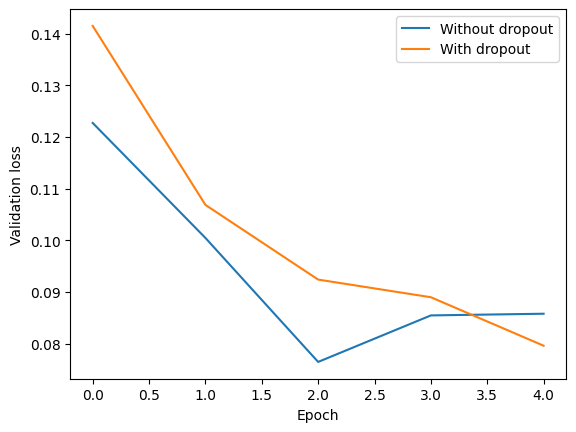

In [4]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255
def build_dropout_model(use_dropout):
    model = models.Sequential([layers.Input((28, 28)), layers.Flatten(), layers.Dense(512, activation="relu")])
    if use_dropout:
        model.add(layers.Dropout(0.5))
    model.add(layers.Dense(256, activation="relu"))
    if use_dropout:
        model.add(layers.Dropout(0.3))
    model.add(layers.Dense(10, activation="softmax"))
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model
histories = {}
for label, use_dropout in [("Without dropout", False), ("With dropout", True)]:
    model = build_dropout_model(use_dropout)
    histories[label] = model.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.2, verbose=0)
    print(label)
    model.evaluate(x_test, y_test, verbose=0)
for label, history in histories.items():
    plt.plot(history.history["val_loss"], label=label)
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.legend()
plt.show()

## 36. Apply L2 regularization to customer purchasing behaviour classification

In [6]:
from tensorflow.keras import regularizers

X, y = make_classification(n_samples=2000, n_features=20, n_informative=10, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
model = models.Sequential([layers.Input((20,)), layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(0.01)), layers.Dense(32, activation="relu", kernel_regularizer=regularizers.l2(0.01)), layers.Dense(1, activation="sigmoid")])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.fit(X_train, y_train, epochs=15, batch_size=32, validation_split=0.2)
print("Test results:", model.evaluate(X_test, y_test))
for layer in model.layers:
    if hasattr(layer, "kernel"):
        print(layer.name, "Weight norm:", float(tf.norm(layer.kernel)))

Epoch 1/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.6820 - loss: 1.2981 - val_accuracy: 0.8062 - val_loss: 1.1207
Epoch 2/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8422 - loss: 1.0196 - val_accuracy: 0.8687 - val_loss: 0.8981
Epoch 3/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8805 - loss: 0.8321 - val_accuracy: 0.8938 - val_loss: 0.7525
Epoch 4/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9008 - loss: 0.7011 - val_accuracy: 0.8906 - val_loss: 0.6515
Epoch 5/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9172 - loss: 0.6058 - val_accuracy: 0.9031 - val_loss: 0.5720
Epoch 6/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9242 - loss: 0.5336 - val_accuracy: 0.9094 - val_loss: 0.5113
Epoch 7/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9328 - loss: 0.4747 - val_accuracy: 0.9094 - val_loss: 0.4687
Epoch 8/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9438 - loss: 0.4289 - val_accuracy: 0.9281 - val_los

## 37. Compare models with and without regularization

In [7]:
X, y = make_classification(n_samples=2500, n_features=30, n_informative=8, n_redundant=10, flip_y=0.12, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
def create_model(reg):
    model = models.Sequential([layers.Input((30,)), layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(0.01) if reg else None), layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(0.01) if reg else None), layers.Dense(1, activation="sigmoid")])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model
for label, reg in [("Without regularization", False), ("With L2 regularization", True)]:
    model = create_model(reg)
    model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.2, verbose=0)
    print(label, "Train:", model.evaluate(X_train, y_train, verbose=0), "Test:", model.evaluate(X_test, y_test, verbose=0))

Without regularization Train: [0.19018442928791046, 0.9429333209991455] Test: [0.4779476523399353, 0.8528000116348267]
With L2 regularization Train: [0.3814345598220825, 0.9007999897003174] Test: [0.44709843397140503, 0.8623999953269958]


## 38. CNN for handwritten digit recognition using MNIST

In [9]:
import numpy as np
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = x_train[..., np.newaxis].astype("float32") / 255
x_test = x_test[..., np.newaxis].astype("float32") / 255
model = models.Sequential([layers.Input((28, 28, 1)), layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(), layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(), layers.Flatten(), layers.Dense(128, activation="relu"), layers.Dense(10, activation="softmax")])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.1)
model.evaluate(x_test, y_test)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 97ms/step - accuracy: 0.9319 - loss: 0.2268 - val_accuracy: 0.9813 - val_loss: 0.0648
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - accuracy: 0.9812 - loss: 0.0610 - val_accuracy: 0.9867 - val_loss: 0.0478
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 39s 93ms/step - accuracy: 0.9866 - loss: 0.0419 - val_accuracy: 0.9882 - val_loss: 0.0369
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 38s 91ms/step - accuracy: 0.9904 - loss: 0.0307 - val_accuracy: 0.9888 - val_loss: 0.0394
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 39s 91ms/step - accuracy: 0.9921 - loss: 0.0239 - val_accuracy: 0.9907 - val_loss: 0.0361
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9885 - loss: 0.0340


[0.03398212790489197, 0.9884999990463257]

## 39. Implement convolution and pooling operations on an input image

In [10]:
image = np.array([[1, 2, 0, 1, 3], [4, 1, 2, 0, 1], [2, 3, 1, 4, 0], [0, 1, 3, 2, 1], [2, 0, 1, 3, 4]], dtype="float32")
kernel = np.array([[1, 0, -1], [1, 0, -1], [1, 0, -1]], dtype="float32")
image_tensor = tf.constant(image.reshape(1, 5, 5, 1))
kernel_tensor = tf.constant(kernel.reshape(3, 3, 1, 1))
convolved = tf.nn.conv2d(image_tensor, kernel_tensor, strides=1, padding="VALID")
max_pooled = tf.nn.max_pool2d(convolved, ksize=2, strides=1, padding="VALID")
avg_pooled = tf.nn.avg_pool2d(convolved, ksize=2, strides=1, padding="VALID")
print("Input image:\n", image)
print("Convolution feature map:\n", convolved.numpy()[0, :, :, 0])
print("Max pooled feature map:\n", max_pooled.numpy()[0, :, :, 0])
print("Average pooled feature map:\n", avg_pooled.numpy()[0, :, :, 0])

Input image:
 [[1. 2. 0. 1. 3.]
 [4. 1. 2. 0. 1.]
 [2. 3. 1. 4. 0.]
 [0. 1. 3. 2. 1.]
 [2. 0. 1. 3. 4.]]
Convolution feature map:
 [[ 4.  1. -1.]
 [ 0. -1.  4.]
 [-1. -5.  0.]]
Max pooled feature map:
 [[4. 4.]
 [0. 4.]]
Average pooled feature map:
 [[ 1.    0.75]
 [-1.75 -0.5 ]]


## 40. Compare max pooling and average pooling

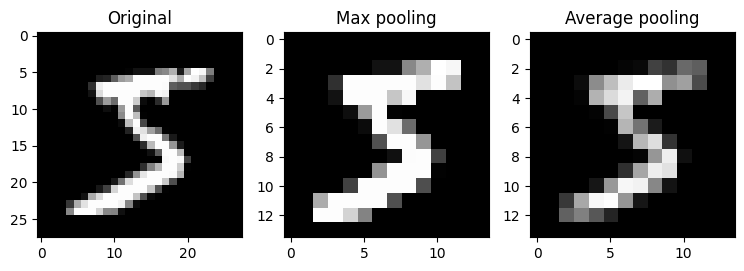

In [11]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
sample = x_train[0].astype("float32") / 255
sample_tensor = tf.constant(sample.reshape(1, 28, 28, 1))
max_result = tf.nn.max_pool2d(sample_tensor, ksize=2, strides=2, padding="VALID").numpy()[0, :, :, 0]
avg_result = tf.nn.avg_pool2d(sample_tensor, ksize=2, strides=2, padding="VALID").numpy()[0, :, :, 0]
plt.figure(figsize=(9, 3))
plt.subplot(1, 3, 1)
plt.imshow(sample, cmap="gray")
plt.title("Original")
plt.subplot(1, 3, 2)
plt.imshow(max_result, cmap="gray")
plt.title("Max pooling")
plt.subplot(1, 3, 3)
plt.imshow(avg_result, cmap="gray")
plt.title("Average pooling")
plt.show()

## 41. CNN-based cat and dog image classification

In [13]:
import os
import shutil
import numpy as np
import tensorflow as tf
from tensorflow.keras import models, layers

base_dir = "/tmp/cats_and_dogs_filtered"
train_dir = os.path.join(base_dir, "train")
validation_dir = os.path.join(base_dir, "validation")

# Ensure clean state
if os.path.exists(base_dir):
    shutil.rmtree(base_dir)

print("Generating local synthetic image dataset to bypass 403 Forbidden download issues...")
for split in ['train', 'validation']:
    for cls in ['cats', 'dogs']:
        path = os.path.join(base_dir, split, cls)
        os.makedirs(path, exist_ok=True)

        for i in range(50):
            img_data = np.random.randint(0, 256, (128, 128, 3), dtype=np.uint8)
            img = tf.keras.utils.array_to_img(img_data)
            img.save(os.path.join(path, f"img_{i}.jpg"))

train_ds = tf.keras.utils.image_dataset_from_directory(train_dir, image_size=(128, 128), batch_size=32)
val_ds = tf.keras.utils.image_dataset_from_directory(validation_dir, image_size=(128, 128), batch_size=32)
class_names = train_ds.class_names

train_ds = train_ds.map(lambda x, y: (x / 255.0, y)).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.map(lambda x, y: (x / 255.0, y)).prefetch(tf.data.AUTOTUNE)

model = models.Sequential([
    layers.Input((128, 128, 3)),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.fit(train_ds, validation_data=val_ds, epochs=5)
model.evaluate(val_ds)
print("Classes found:", class_names)

Generating local synthetic image dataset to bypass 403 Forbidden download issues...
Found 100 files belonging to 2 classes.
Found 100 files belonging to 2 classes.
Epoch 1/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - accuracy: 0.4600 - loss: 1.3738 - val_accuracy: 0.5000 - val_loss: 0.6968
Epoch 2/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 836ms/step - accuracy: 0.5000 - loss: 0.6992 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 3/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.4200 - loss: 0.6964 - val_accuracy: 0.5000 - val_loss: 0.6933
Epoch 4/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.5000 - loss: 0.6924 - val_accuracy: 0.5000 - val_loss: 0.6936
Epoch 5/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 837ms/step - accuracy: 0.5000 - loss: 0.6964 - val_accuracy: 0.5000 - val_loss: 0.6946
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 165ms/step - accuracy: 0.5000 - loss: 0.6946
Classes found: ['cats', 'dogs']


## 42. Experiment with CNN filter sizes and number of filters

In [14]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = x_train[..., np.newaxis].astype("float32") / 255
x_test = x_test[..., np.newaxis].astype("float32") / 255
results = []
for filter_size, filters in [(3, 16), (3, 32), (5, 16), (5, 32)]:
    model = models.Sequential([layers.Input((28, 28, 1)), layers.Conv2D(filters, filter_size, activation="relu"), layers.MaxPooling2D(), layers.Flatten(), layers.Dense(64, activation="relu"), layers.Dense(10, activation="softmax")])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    model.fit(x_train, y_train, epochs=3, batch_size=128, verbose=0)
    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
    results.append((filter_size, filters, accuracy))
for result in results:
    print("Filter size:", result[0], "Number of filters:", result[1], "Accuracy:", round(result[2], 4))

Filter size: 3 Number of filters: 16 Accuracy: 0.9775
Filter size: 3 Number of filters: 32 Accuracy: 0.9785
Filter size: 5 Number of filters: 16 Accuracy: 0.9828
Filter size: 5 Number of filters: 32 Accuracy: 0.9857


## 43. Evaluate medical image classification using accuracy, precision, recall, F1-score and confusion matrix

Accuracy: 0.9225
Precision: 0.9090909090909091
Recall: 0.9036144578313253
F1-score: 0.9063444108761329


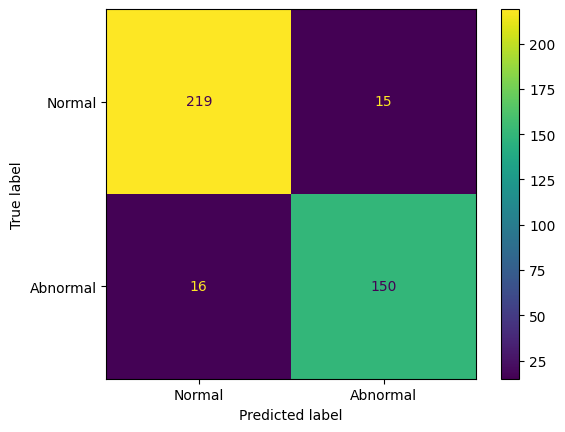

In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

X, y = make_classification(n_samples=2000, n_features=20, n_informative=12, weights=[0.6, 0.4], random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
model = models.Sequential([layers.Input((20,)), layers.Dense(64, activation="relu"), layers.Dense(32, activation="relu"), layers.Dense(1, activation="sigmoid")])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.fit(X_train, y_train, epochs=10, batch_size=32, verbose=0)
predictions = (model.predict(X_test, verbose=0) >= 0.5).astype(int).ravel()
print("Accuracy:", accuracy_score(y_test, predictions))
print("Precision:", precision_score(y_test, predictions))
print("Recall:", recall_score(y_test, predictions))
print("F1-score:", f1_score(y_test, predictions))
cm = confusion_matrix(y_test, predictions)
ConfusionMatrixDisplay(cm, display_labels=["Normal", "Abnormal"]).plot()
plt.show()

## 44. Compare CNN training with and without batch normalization

Without batch normalization [0.0443740040063858, 0.9858999848365784]
With batch normalization [0.038969721645116806, 0.9876000285148621]


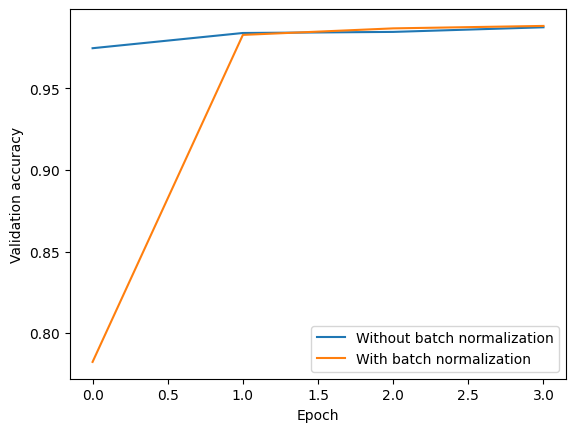

In [18]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = x_train[..., np.newaxis].astype("float32") / 255
x_test = x_test[..., np.newaxis].astype("float32") / 255
def batch_model(use_bn):
    model = models.Sequential([layers.Input((28, 28, 1)), layers.Conv2D(32, 3, activation=None), layers.BatchNormalization() if use_bn else layers.Activation("linear"), layers.Activation("relu"), layers.MaxPooling2D(), layers.Conv2D(64, 3, activation=None), layers.BatchNormalization() if use_bn else layers.Activation("linear"), layers.Activation("relu"), layers.MaxPooling2D(), layers.Flatten(), layers.Dense(10, activation="softmax")])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model
for label, use_bn in [("Without batch normalization", False), ("With batch normalization", True)]:
    model = batch_model(use_bn)
    history = model.fit(x_train, y_train, epochs=4, batch_size=128, validation_split=0.1, verbose=0)
    print(label, model.evaluate(x_test, y_test, verbose=0))
    plt.plot(history.history["val_accuracy"], label=label)
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.legend()
plt.show()

## 45. Apply image augmentation using rotation, flipping and zooming

In [19]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = x_train[..., np.newaxis].astype("float32") / 255
x_test = x_test[..., np.newaxis].astype("float32") / 255
augmentation = models.Sequential([layers.RandomRotation(0.08), layers.RandomFlip("horizontal"), layers.RandomZoom(0.1)])
model = models.Sequential([layers.Input((28, 28, 1)), augmentation, layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(), layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(), layers.Flatten(), layers.Dense(128, activation="relu"), layers.Dense(10, activation="softmax")])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.1)
model.evaluate(x_test, y_test)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 45s 101ms/step - accuracy: 0.8372 - loss: 0.5053 - val_accuracy: 0.9503 - val_loss: 0.1638
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 99ms/step - accuracy: 0.9369 - loss: 0.2038 - val_accuracy: 0.9575 - val_loss: 0.1455
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 100ms/step - accuracy: 0.9548 - loss: 0.1462 - val_accuracy: 0.9737 - val_loss: 0.0934
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 99ms/step - accuracy: 0.9629 - loss: 0.1187 - val_accuracy: 0.9793 - val_loss: 0.0758
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 100ms/step - accuracy: 0.9696 - loss: 0.0992 - val_accuracy: 0.9807 - val_loss: 0.0725
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9791 - loss: 0.0661


[0.06614702939987183, 0.9790999889373779]

## 46. Plant disease classification using transfer learning with EfficientNetB0

In [22]:
!pip install -q tensorflow-datasets

import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras import layers, models

dataset, info = tfds.load(
    "plant_village",
    split=["train[:10%]", "train[10%:12%]"],
    as_supervised=True,
    with_info=True
)

train_ds, val_ds = dataset

def prepare_image(image, label):
    image = tf.image.resize(image, (96, 96))
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

train_ds = train_ds.map(prepare_image).batch(64).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.map(prepare_image).batch(64).prefetch(tf.data.AUTOTUNE)

num_classes = info.features["label"].num_classes

model = models.Sequential([
    layers.Input(shape=(96, 96, 3)),
    layers.Conv2D(16, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.fit(train_ds, validation_data=val_ds, epochs=2)

model.evaluate(val_ds)

Epoch 1/2
85/85 ━━━━━━━━━━━━━━━━━━━━ 59s 642ms/step - accuracy: 0.1258 - loss: 3.3894 - val_accuracy: 0.1961 - val_loss: 3.2114
Epoch 2/2
85/85 ━━━━━━━━━━━━━━━━━━━━ 75s 571ms/step - accuracy: 0.2123 - loss: 2.9991 - val_accuracy: 0.2422 - val_loss: 2.7907
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 143ms/step - accuracy: 0.2422 - loss: 2.7907


[2.790741205215454, 0.24217310547828674]

## 47. Implement a basic RNN for sequential machine sensor data

In [23]:
time_steps = 30
samples = 1500
time = np.arange(samples + time_steps)
series = np.sin(time * 0.05) + 0.2 * np.sin(time * 0.2) + np.random.normal(0, 0.05, len(time))
X = np.array([series[i:i + time_steps] for i in range(samples)])
y = np.array([series[i + time_steps] for i in range(samples)])
X = X[..., np.newaxis]
X_train, X_test = X[:1200], X[1200:]
y_train, y_test = y[:1200], y[1200:]
model = models.Sequential([layers.Input((time_steps, 1)), layers.SimpleRNN(32, activation="tanh"), layers.Dense(1)])
model.compile(optimizer="adam", loss="mse", metrics=["mae"])
model.fit(X_train, y_train, epochs=15, batch_size=32, validation_split=0.2)
model.evaluate(X_test, y_test)

Epoch 1/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 57ms/step - loss: 0.0512 - mae: 0.1664 - val_loss: 0.0129 - val_mae: 0.0922
Epoch 2/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0094 - mae: 0.0774 - val_loss: 0.0073 - val_mae: 0.0694
Epoch 3/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0073 - mae: 0.0690 - val_loss: 0.0065 - val_mae: 0.0669
Epoch 4/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0065 - mae: 0.0652 - val_loss: 0.0063 - val_mae: 0.0643
Epoch 5/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0063 - mae: 0.0639 - val_loss: 0.0060 - val_mae: 0.0631
Epoch 6/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0062 - mae: 0.0634 - val_loss: 0.0059 - val_mae: 0.0628
Epoch 7/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0060 - mae: 0.0629 - val_loss: 0.0058 - val_mae: 0.0620
Epoch 8/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0059 - mae: 0.0621 - val_loss: 0.0058 - val_mae: 0.0616
Epoch 9/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.005

[0.0047197951935231686, 0.05643489956855774]

## 48. RNN model for next-day temperature prediction

Epoch 1/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - loss: 587.1059 - mae: 23.6991 - val_loss: 644.5228 - val_mae: 25.0262
Epoch 2/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 482.5248 - mae: 21.3883 - val_loss: 557.5992 - val_mae: 23.2236
Epoch 3/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 410.7283 - mae: 19.6336 - val_loss: 473.8401 - val_mae: 21.3477
Epoch 4/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 340.2515 - mae: 17.7468 - val_loss: 397.4274 - val_mae: 19.4743
Epoch 5/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 276.7727 - mae: 15.8563 - val_loss: 326.1367 - val_mae: 17.5517
Epoch 6/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 217.9314 - mae: 13.8840 - val_loss: 258.5514 - val_mae: 15.5070
Epoch 7/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 164.4975 - mae: 11.8044 - val_loss: 198.1057 - val_mae: 13.4172
Epoch 8/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 119.8154 - mae: 9.7304 - val_loss: 147.4918 - val_mae: 11.3756
Epoch 9/20
24/24 ━━━━━━

MAE: 1.31609741412937
MSE: 3.4861127735718576
RMSE: 1.8671134870628132


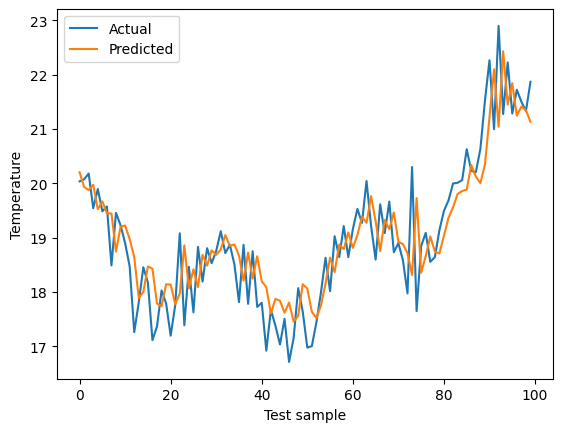

In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import models, layers

days = 1200
t = np.arange(days)
temperature = 25 + 7 * np.sin(2 * np.pi * t / 365) + 0.8 * np.sin(2 * np.pi * t / 30) + np.random.normal(0, 0.5, days)
window = 30
X = np.array([temperature[i:i + window] for i in range(days - window)])
y = np.array([temperature[i + window] for i in range(days - window)])
X = X[..., np.newaxis]
split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]
model = models.Sequential([layers.Input((window, 1)), layers.SimpleRNN(32, activation="tanh"), layers.Dense(16, activation="relu"), layers.Dense(1)])
model.compile(optimizer="adam", loss="mse", metrics=["mae"])
model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.2)
predictions = model.predict(X_test, verbose=0).ravel()
print("MAE:", mean_absolute_error(y_test, predictions))
print("MSE:", mean_squared_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
plt.plot(y_test[:100], label="Actual")
plt.plot(predictions[:100], label="Predicted")
plt.xlabel("Test sample")
plt.ylabel("Temperature")
plt.legend()
plt.show()